In [1]:
# 데이터 경로 (new_joints/, texts/ 가 들어 있는 폴더)
DATA_ROOT = '/home/jaesik/mnt/HumanML3D/HumanML3D'

# ===== 판정 임계값 (높이 단위 m, 모두 클립 바닥 기준) =====
# 서 있을 때 발목 높이. 정지 상태로 발가락이 바닥에 닿은 프레임의 발목 높이 중앙값(0.059 m)에서 잡음
STANDING_ANKLE_HEIGHT = 0.06
# 발목 판정의 여유값
ANKLE_MARGIN = 0.03
# 발가락 판정의 여유값
TOE_MARGIN = 0.03
# 발목의 프레임 간 이동량 임계값 (m/프레임). HumanML3D의 feet_thre=0.002 (이동량 제곱 합) → sqrt(0.002)
ANKLE_DISP_THRESH = 0.0447

# ===== 출력 설정 =====
# 노트북에 출력할 클립 순위 표와 프레임 표의 행 수
MAX_RANK_ROWS = 50
MAX_TABLE_ROWS = 50
# 시각화할 클립 수와 시작 순위 (0이면 1위부터, 다음 묶음을 보려면 값을 키워서 재실행)
VIS_TOP_N = 8
VIS_RANK_START = 0
# 표를 CSV로 저장할지 여부와 저장 폴더
SAVE_CSV = True
OUTPUT_DIR = '/home/jaesik/mnt/Motion-Data-Analysis/draft/outputs'
# 표에서 고른 클립을 따로 볼 때 이름 입력 (예: '012314'), None이면 건너뜀
INSPECT_CLIP = None

# ===== 시각화 설정 =====
# 그래프 세로축 상한 (m). 바닥 근처를 보기 위한 값이고, 이보다 높은 구간은 잘려 보임
PLOT_YMAX = 0.40
# 프레임 이미지 장수
N_KEY_FRAMES = 6
# 후보 구간 앞뒤로 함께 보여줄 프레임 수
SEGMENT_PAD = 8
# 클립마다 보여줄 구간 수 (긴 구간부터)
VIS_SEGMENTS_PER_CLIP = 1
# 구간별 표에 출력할 최대 행 수
MAX_ROWS_PER_SEGMENT = 20
# 애니메이션 포함 여부, 재생 속도(원본 20fps), 최대 프레임 수
ANIMATE = True
ANIM_FPS = 10
ANIM_MAX_FRAMES = 60
# True면 이미 본 클립의 좌우 반전본(M...)은 시각화에서 건너뜀 (표에는 모두 나옴)
VIS_SKIP_MIRROR = True


# 전체 데이터에서 발 접촉 불일치 프레임 찾기

발가락 기준으론 접촉인데 발목 기준으론 공중인 프레임을 전체 데이터에서 모두 추출하고, 해당 프레임이 많은 클립 순으로 정렬합니다. 임계값은 맨 위 셀에서 조절합니다.

**표의 열**: `clip` 클립 이름 · `foot` 발(L/R) · `frame` 프레임 번호 · `text` 그 프레임을 설명하는 캡션 · `ankle_h`, `toe_h` 바닥 기준 발목·발가락 높이(m) · `ankle_disp` 발목 이동량(m/프레임) · `ankle_fail` 발목 판정이 실패한 이유(`height` 높이 초과 / `motion` 이동량 초과 / `height+motion` 둘 다) · `in_text_span` 표시된 캡션이 이 프레임 구간을 설명하면 True (HumanML3D 캡션 일부는 클립의 일부 구간만 설명함)

**발가락 관절**: 10·11번은 발 끝이 아니라 발볼 위치의 관절입니다.

`text`는 그 프레임을 설명하는 첫 캡션입니다.

In [2]:
import os
import glob
import re
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# 데이터 프레임 속도
FPS = 20
# 발별 (발목, 발가락) 관절 번호
FEET = {'L': (7, 10), 'R': (8, 11)}
# 발별 (무릎, 발목, 발가락) 관절 번호. 발 확대 그림에 사용
FOOT_CHAIN = {'L': [4, 7, 10], 'R': [5, 8, 11]}
# 바닥 계산에 쓰는 발 관절
FOOT_JOINTS = [7, 8, 10, 11]
# 22관절 골격의 뼈대 연결
CHAINS = [[0, 2, 5, 8, 11], [0, 1, 4, 7, 10], [0, 3, 6, 9, 12, 15],
          [9, 14, 17, 19, 21], [9, 13, 16, 18, 20]]

# 임계값에서 계산한 높이 상한
ANKLE_HEIGHT_LIMIT = STANDING_ANKLE_HEIGHT + ANKLE_MARGIN
TOE_HEIGHT_LIMIT = TOE_MARGIN

# 그림 색상 (발목/발가락은 모든 그림에서 같은 색)
COLOR_ANKLE, COLOR_TOE = '#2a78d6', '#eb6834'
INK, INK_SOFT, BONE, GRID, SURFACE = '#0b0b0b', '#52514e', '#b4b2a9', '#e6e4dd', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK_SOFT, 'text.color': INK,
                     'xtick.color': INK_SOFT, 'ytick.color': INK_SOFT, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'animation.embed_limit': 100})
pd.set_option('display.max_colwidth', 90)


def load_joints(names):
    """클립 이름 목록의 관절 위치를 불러옴. {이름: (T, 22, 3)}"""
    with ThreadPoolExecutor(16) as ex:
        arrays = list(ex.map(lambda n: np.load(f'{DATA_ROOT}/new_joints/{n}.npy'), names))
    return dict(zip(names, arrays))


def load_captions(name):
    """텍스트 파일 한 개를 읽음. start/end는 초 단위이고 둘 다 0이면 클립 전체를 설명"""
    captions = []
    path = f'{DATA_ROOT}/texts/{name}.txt'
    if not os.path.exists(path):
        return captions
    with open(path, encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip('\n').split('#')
            if len(parts) >= 4 and parts[0].strip():
                # 구간 값이 nan인 줄이 있어서 클립 전체(0)로 처리 (HumanML3D 로더와 동일)
                start, end = np.nan_to_num([float(parts[-2]), float(parts[-1])])
                captions.append({'text': parts[0].strip(), 'start': start, 'end': end})
    return captions


def analyze_clip(joints):
    """클립 한 개에 판정을 적용. 프레임 수가 2 미만이면 이동량을 구할 수 없어 None"""
    if len(joints) < 2:
        return None
    # 바닥: 클립 전체에서 발 관절(발목·발가락 양쪽)의 최저 높이
    floor = joints[:, FOOT_JOINTS, 1].min()
    result = {'floor': floor}
    for foot, (ankle_i, toe_i) in FEET.items():
        ankle_h = joints[:, ankle_i, 1] - floor
        toe_h = joints[:, toe_i, 1] - floor
        # 프레임 t의 이동량 = t → t+1 발목 이동 거리(3D). 마지막 프레임은 직전 값을 사용
        disp = np.linalg.norm(np.diff(joints[:, ankle_i], axis=0), axis=1)
        disp = np.append(disp, disp[-1])
        ankle_low = ankle_h <= ANKLE_HEIGHT_LIMIT
        ankle_still = disp <= ANKLE_DISP_THRESH
        ankle_contact = ankle_low & ankle_still
        toe_contact = toe_h <= TOE_HEIGHT_LIMIT
        # 찾는 대상: 발가락 기준 접촉 & 발목 기준 공중
        target = toe_contact & ~ankle_contact
        # 발목 판정이 실패한 이유
        fail = np.where(~ankle_low & ~ankle_still, 'height+motion', np.where(~ankle_low, 'height', 'motion'))
        result[foot] = {'ankle_h': ankle_h, 'toe_h': toe_h, 'disp': disp, 'target': target,
                        'ankle_contact': ankle_contact, 'toe_contact': toe_contact, 'fail': fail}
    return result


def frame_captions(captions, n_frames):
    """프레임마다 그 프레임을 설명하는 첫 캡션 번호를 구함. 맞는 캡션이 없으면 0번과 False"""
    cap_i = np.zeros(n_frames, dtype=int)
    covered = np.zeros(n_frames, dtype=bool)
    for i in range(len(captions) - 1, -1, -1):
        c = captions[i]
        if c['start'] == 0 and c['end'] == 0:
            mask = np.ones(n_frames, dtype=bool)
        else:
            mask = np.zeros(n_frames, dtype=bool)
            mask[int(c['start'] * FPS):int(c['end'] * FPS)] = True
        cap_i[mask] = i
        covered |= mask
    return cap_i, covered


def build_frame_table(clips, joints, captions):
    """찾는 대상 프레임을 모두 모아 표로 만듦. 한 행 = (클립, 발, 프레임)"""
    cols = {k: [] for k in ['clip_i', 'foot', 'frame', 'text', 'ankle_h', 'toe_h',
                            'ankle_disp', 'ankle_fail', 'in_text_span']}
    for i, clip in enumerate(clips):
        result = analyze_clip(joints[clip])
        if result is None:
            continue
        caps = captions[clip]
        cap_i, covered = frame_captions(caps, len(joints[clip]))
        texts = np.array([c['text'] for c in caps] or [''], dtype=object)
        for foot in FEET:
            r = result[foot]
            idx = np.flatnonzero(r['target'])
            if idx.size == 0:
                continue
            cols['clip_i'].append(np.full(idx.size, i))
            cols['foot'].append(np.full(idx.size, foot))
            cols['frame'].append(idx)
            cols['text'].append(texts[cap_i[idx]])
            cols['ankle_h'].append(r['ankle_h'][idx])
            cols['toe_h'].append(r['toe_h'][idx])
            cols['ankle_disp'].append(r['disp'][idx])
            cols['ankle_fail'].append(r['fail'][idx])
            cols['in_text_span'].append(covered[idx])
    if not cols['clip_i']:
        return pd.DataFrame(columns=['clip', 'foot', 'frame', 'text', 'ankle_h', 'toe_h',
                                     'ankle_disp', 'ankle_fail', 'in_text_span'])
    data = {k: np.concatenate(v) for k, v in cols.items()}
    names = np.array(clips, dtype=object)
    df = pd.DataFrame({'clip': names[data['clip_i']], **{k: data[k] for k in cols if k != 'clip_i'}})
    return df.sort_values(['clip', 'foot', 'frame']).reset_index(drop=True)


def rank_clips(df, joints, captions):
    """클립별 대상 프레임 수 표. n_target은 왼발+오른발 프레임 합이라 n_frames의 2배까지 가능"""
    by_foot = df.groupby(['clip', 'foot']).size().unstack(fill_value=0).reindex(columns=['L', 'R'], fill_value=0)
    rank = pd.DataFrame({'n_target': by_foot.sum(axis=1), 'n_target_L': by_foot['L'], 'n_target_R': by_foot['R']})
    rank['n_frames'] = [len(joints[c]) for c in rank.index]
    rank['target_ratio'] = (rank['n_target'] / (2 * rank['n_frames'])).round(3)
    rank['n_height_fail'] = (df['ankle_fail'] != 'motion').groupby(df['clip']).sum()
    rank['n_motion_only'] = rank['n_target'] - rank['n_height_fail']
    rank['text'] = [captions[c][0]['text'] if captions[c] else '' for c in rank.index]
    rank = rank.reset_index().sort_values(['n_target', 'clip'], ascending=[False, True]).reset_index(drop=True)
    rank.insert(0, 'rank', rank.index + 1)
    return rank


def find_segments(mask):
    """불리언 배열에서 연속 True 구간 [(시작, 끝), ...] (끝은 미포함)"""
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(np.int8), 0]))
    return list(zip(edges[::2].tolist(), edges[1::2].tolist()))


def body_axis(joints, foot, lo, hi):
    """구간 동안 발이 향한 평균 수평 방향. 옆모습 투영축으로 사용"""
    ankle_i, toe_i = FEET[foot]
    v = (joints[lo:hi, toe_i] - joints[lo:hi, ankle_i])[:, [0, 2]].mean(axis=0)
    n = np.linalg.norm(v)
    return v / n if n > 1e-6 else np.array([1.0, 0.0])


def project_body(joints, frame, u):
    """전신을 옆모습으로 투영. 가로축은 골반 기준 u 방향 거리"""
    p = joints[frame] - joints[frame, 0]
    return p[:, 0] * u[0] + p[:, 2] * u[1]


def project_foot(joints, frame, foot):
    """무릎·발목·발가락을 발 방향 평면에 투영. 가로축은 발목 기준 프레임별 발 방향 거리"""
    knee_i, ankle_i, toe_i = FOOT_CHAIN[foot]
    v = (joints[frame, toe_i] - joints[frame, ankle_i])[[0, 2]]
    n = np.linalg.norm(v)
    u = v / n if n > 1e-6 else np.array([1.0, 0.0])
    p = joints[frame, [knee_i, ankle_i, toe_i]] - joints[frame, ankle_i]
    return p[:, 0] * u[0] + p[:, 2] * u[1]


def draw_body(ax, joints, floor, frame, foot, u, ymax):
    """전신 스켈레톤 한 프레임을 그림. 대상 발의 다리는 진하게, 발목/발가락은 색 점으로 표시"""
    x, y = project_body(joints, frame, u), joints[frame, :, 1] - floor
    for chain in CHAINS:
        ax.plot(x[chain], y[chain], color=BONE, lw=1.6, solid_capstyle='round')
    chain = FOOT_CHAIN[foot]
    ax.plot(x[chain], y[chain], color=INK_SOFT, lw=2, solid_capstyle='round')
    ax.scatter(x[chain[1]], y[chain[1]], s=26, color=COLOR_ANKLE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.scatter(x[chain[2]], y[chain[2]], s=26, color=COLOR_TOE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.set(xlim=(-1, 1), ylim=(-0.05, ymax), aspect='equal', xticks=[], yticks=[])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_foot(ax, joints, floor, frame, foot):
    """발 부분 확대 한 프레임. 점선은 발목/발가락 높이 상한"""
    x, y = project_foot(joints, frame, foot), joints[frame, FOOT_CHAIN[foot], 1] - floor
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.axhline(ANKLE_HEIGHT_LIMIT, color=COLOR_ANKLE, lw=0.8, ls=':')
    ax.axhline(TOE_HEIGHT_LIMIT, color=COLOR_TOE, lw=0.8, ls=':')
    ax.plot(x, y, color=INK_SOFT, lw=2, solid_capstyle='round')
    ax.scatter(x[1], y[1], s=36, color=COLOR_ANKLE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.scatter(x[2], y[2], s=36, color=COLOR_TOE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.set(xlim=(-0.2, 0.3), ylim=(-0.03, 0.3), aspect='equal', xticks=[], yticks=[])
    for s in ax.spines.values():
        s.set_visible(False)


def plot_heights(ax, r, foot_name, seg=None, key_frames=(), show_labels=True):
    """한쪽 발의 발목·발가락 높이 그래프. 회색 띠는 대상 프레임, 진한 띠는 지금 보는 구간"""
    t = np.arange(len(r['ankle_h']))
    for s, e in find_segments(r['target']):
        ax.axvspan(s - 0.5, e - 0.5, color=BONE, alpha=0.28, lw=0)
    if seg is not None:
        ax.axvspan(seg[0] - 0.5, seg[1] - 0.5, color=BONE, alpha=0.55, lw=0)
    ax.axhline(ANKLE_HEIGHT_LIMIT, color=COLOR_ANKLE, lw=0.9, ls=':')
    ax.axhline(TOE_HEIGHT_LIMIT, color=COLOR_TOE, lw=0.9, ls=':')
    ax.axhline(0, color=INK_SOFT, lw=0.8)
    ax.plot(t, r['ankle_h'], color=COLOR_ANKLE, lw=2, label='ankle')
    ax.plot(t, r['toe_h'], color=COLOR_TOE, lw=2, label='toe')
    for f in key_frames:
        ax.axvline(f, color=INK_SOFT, lw=0.6, alpha=0.6)
    ax.set_ylim(-0.02, PLOT_YMAX)
    ax.set_xlim(-0.5, max(t[-1], 1) + 0.5)
    ax.grid(axis='y', color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(foot_name, loc='left', fontsize=10)
    ax.set_xlabel('frame (20 fps)')
    if show_labels:
        # 선 끝 직접 라벨. 두 값이 가까우면 위아래로 벌림
        ya, yt = min(r['ankle_h'][-1], PLOT_YMAX * 0.97), min(r['toe_h'][-1], PLOT_YMAX * 0.97)
        if abs(ya - yt) < 0.03:
            ya, yt = (ya + 0.018, yt - 0.018) if ya >= yt else (ya - 0.018, yt + 0.018)
        ax.annotate('ankle', (1.005, ya), xycoords=('axes fraction', 'data'), fontsize=8, va='center', color=INK_SOFT)
        ax.annotate('toe', (1.005, max(yt, -0.01)), xycoords=('axes fraction', 'data'), fontsize=8, va='center', color=INK_SOFT)


def show_segment_figure(clip, joints, result, foot, seg, text):
    """후보 구간의 프레임 이미지(전신·발 확대)와 발목·발가락 높이 그래프를 한 그림에 그림"""
    s, e = seg
    floor = result['floor']
    lo, hi = max(0, s - SEGMENT_PAD), min(len(joints), e + SEGMENT_PAD)
    keys = np.unique(np.linspace(lo, hi - 1, N_KEY_FRAMES).round().astype(int))
    u = body_axis(joints, foot, s, e)
    ymax = max(1.9, (joints[keys, :, 1] - floor).max() + 0.1)
    r = result[foot]

    fig = plt.figure(figsize=(13, 8.2))
    gs = fig.add_gridspec(3, len(keys), height_ratios=[2.2, 1.0, 1.7], hspace=0.28, wspace=0.05,
                          left=0.05, right=0.96, top=0.9, bottom=0.07)
    for col, f in enumerate(keys):
        ax = fig.add_subplot(gs[0, col])
        draw_body(ax, joints, floor, f, foot, u, ymax)
        state = 'target' if r['target'][f] else ''
        ax.set_title(f'frame {f}  {state}', fontsize=9, fontweight='bold' if state else 'normal')
        ax = fig.add_subplot(gs[1, col])
        draw_foot(ax, joints, floor, f, foot)
        ax.set_xlabel(f"ankle {r['ankle_h'][f]:.3f} / toe {r['toe_h'][f]:.3f} m", fontsize=8)
    sub = gs[2, :].subgridspec(1, 2, wspace=0.12)
    names = {'L': 'Left foot', 'R': 'Right foot'}
    first_ax = None
    for i, side in enumerate(['L', 'R']):
        ax = fig.add_subplot(sub[0, i], sharey=first_ax)
        first_ax = first_ax or ax
        plot_heights(ax, result[side], names[side], seg if side == foot else None,
                     keys if side == foot else ())
        if i == 0:
            ax.set_ylabel('height above clip floor (m)')
            handles = [plt.Line2D([], [], color=COLOR_ANKLE, lw=2, label='ankle'),
                       plt.Line2D([], [], color=COLOR_TOE, lw=2, label='toe'),
                       plt.Line2D([], [], color=COLOR_ANKLE, lw=0.9, ls=':', label=f'ankle limit {ANKLE_HEIGHT_LIMIT:.3f} m'),
                       plt.Line2D([], [], color=COLOR_TOE, lw=0.9, ls=':', label=f'toe limit {TOE_HEIGHT_LIMIT:.3f} m'),
                       plt.Rectangle((0, 0), 1, 1, color=BONE, alpha=0.4, label='target frames')]
            ax.legend(handles=handles, loc='upper left', ncols=5, frameon=False, fontsize=8)
    fig.suptitle(f'{clip}  ·  {names[foot]}  ·  frames {s}–{e - 1} ({e - s} f, {(e - s) / FPS:.2f} s)\n{text[:120]}',
                 fontsize=11, x=0.05, ha='left')
    plt.show()


def show_segment_animation(clip, joints, result, foot, seg):
    """전신·발 확대·높이 그래프를 프레임별로 재생. 슬라이더로 한 프레임씩 넘겨 볼 수 있음"""
    s, e = seg
    lo = max(0, s - SEGMENT_PAD)
    hi = min(len(joints), e + SEGMENT_PAD, lo + ANIM_MAX_FRAMES)
    frames = list(range(lo, hi))
    floor = result['floor']
    r = result[foot]
    u = body_axis(joints, foot, s, e)
    ymax = max(1.9, (joints[lo:hi, :, 1] - floor).max() + 0.1)
    chain = FOOT_CHAIN[foot]

    fig, (ax_body, ax_foot, ax_h) = plt.subplots(1, 3, figsize=(9.5, 3.4), dpi=72,
                                                 gridspec_kw={'width_ratios': [1, 1.1, 2]})
    for ax, draw in [(ax_body, lambda a: draw_body(a, joints, floor, lo, foot, u, ymax)),
                     (ax_foot, lambda a: draw_foot(a, joints, floor, lo, foot))]:
        draw(ax)
    plot_heights(ax_h, r, {'L': 'Left foot', 'R': 'Right foot'}[foot], seg, show_labels=False)
    ax_h.set_xlim(lo - 0.5, hi - 0.5)
    ax_h.legend(loc='upper right', frameon=False, fontsize=8)
    # draw_body는 뼈대 → 대상 다리 순서로, draw_foot은 수평선 3개 → 다리 순서로 선을 그림
    body_lines = ax_body.lines[:len(CHAINS)]
    body_leg = ax_body.lines[len(CHAINS)]
    body_pts = ax_body.collections[:2]
    foot_line = ax_foot.lines[3]
    foot_pts = ax_foot.collections[:2]
    cursor = ax_h.axvline(lo, color=INK, lw=1.2)
    title = fig.suptitle('', fontsize=10, x=0.02, ha='left')
    fig.tight_layout(rect=(0, 0, 1, 0.93))

    def update(f):
        x, y = project_body(joints, f, u), joints[f, :, 1] - floor
        for line, ch in zip(body_lines, CHAINS):
            line.set_data(x[ch], y[ch])
        body_leg.set_data(x[chain], y[chain])
        for pt, j in zip(body_pts, chain[1:]):
            pt.set_offsets([[x[j], y[j]]])
        fx, fy = project_foot(joints, f, foot), joints[f, chain, 1] - floor
        foot_line.set_data(fx, fy)
        for pt, i in zip(foot_pts, [1, 2]):
            pt.set_offsets([[fx[i], fy[i]]])
        cursor.set_xdata([f, f])
        state = 'TARGET' if r['target'][f] else ('both contact' if r['ankle_contact'][f] and r['toe_contact'][f] else
                                                 'ankle contact' if r['ankle_contact'][f] else 'no contact')
        title.set_text(f"{clip}  {foot}  frame {f}  [{state}]  ankle {r['ankle_h'][f]:.3f} m, toe {r['toe_h'][f]:.3f} m, "
                       f"disp {r['disp'][f]:.3f} m/f")
        return []

    anim = FuncAnimation(fig, update, frames=frames, interval=1000 / ANIM_FPS, blit=False)
    html = anim.to_jshtml(default_mode='loop')
    plt.close(fig)
    display(HTML(html))


def visualize_clip(clip, joints, captions, frame_df):
    """클립의 후보 구간을 긴 순서로 표·프레임 이미지·그래프·애니메이션으로 출력"""
    J = joints[clip]
    result = analyze_clip(J)
    if result is None:
        print(f'{clip}: 프레임 수가 2 미만이라 판정 불가')
        return
    segs = sorted(((e - s, foot, s, e) for foot in FEET for s, e in find_segments(result[foot]['target'])),
                  key=lambda v: (-v[0], v[1], v[2]))
    if not segs:
        print(f'{clip}: 찾는 대상 프레임 없음')
        return
    table = frame_df[frame_df['clip'] == clip]
    for length, foot, s, e in segs[:VIS_SEGMENTS_PER_CLIP]:
        rows = table[(table['foot'] == foot) & (table['frame'] >= s) & (table['frame'] < e)]
        note = f' (앞 {MAX_ROWS_PER_SEGMENT}행만 표시)' if len(rows) > MAX_ROWS_PER_SEGMENT else ''
        print(f'{clip} | 발 {foot} | 프레임 {s}–{e - 1} | {length}프레임{note}')
        display(rows.head(MAX_ROWS_PER_SEGMENT).round(4))
        text = rows['text'].iloc[0] if len(rows) else ''
        show_segment_figure(clip, J, result, foot, (s, e), text)
        if ANIMATE:
            show_segment_animation(clip, J, result, foot, (s, e))


def base_name(clip):
    """좌우 반전본(M...)의 원본 이름"""
    return clip[1:] if clip.startswith('M') else clip


def visualize_ranked(clips, joints, captions, frame_df, n, start=0, seen=None):
    """순위 순서로 시각화. VIS_SKIP_MIRROR면 이미 본 클립의 반전본은 건너뜀. 본 클립 집합을 돌려줌"""
    seen = set() if seen is None else seen
    shown = 0
    for clip in clips[start:]:
        if shown >= n:
            break
        if VIS_SKIP_MIRROR and base_name(clip) in seen:
            continue
        visualize_clip(clip, joints, captions, frame_df)
        seen.add(base_name(clip))
        shown += 1
    return seen


## 1. 전체 데이터에 판정 적용

In [3]:
# 전체 클립과 캡션, 관절 불러오기
clips = sorted(os.path.basename(p)[:-4] for p in glob.glob(f'{DATA_ROOT}/new_joints/*.npy'))
captions = {c: load_captions(c) for c in clips}
joints = load_joints(clips)

# 판정 적용
frame_df = build_frame_table(clips, joints, captions)
print(f'클립 {len(clips):,}개 중 대상 프레임이 있는 클립 {frame_df["clip"].nunique():,}개')
print(f'대상 프레임 {len(frame_df):,}개 (발 단위)')
print('발목 판정 실패 이유:', frame_df['ankle_fail'].value_counts().to_dict())

클립 29,228개 중 대상 프레임이 있는 클립 21,953개
대상 프레임 531,577개 (발 단위)
발목 판정 실패 이유: {'height': 384310, 'height+motion': 79086, 'motion': 68181}


## 2. 클립 순위

`n_target`은 왼발과 오른발의 대상 프레임을 더한 값입니다. `target_ratio`는 `n_target / (2 × n_frames)`입니다. `n_height_fail`은 발목이 높이 조건을 넘긴 프레임, `n_motion_only`는 높이는 낮지만 이동량만 넘긴 프레임 수입니다.

In [4]:
# 대상 프레임이 많은 클립 순으로 정렬
rank = rank_clips(frame_df, joints, captions)
print(f'전체 {len(rank):,}개 클립 중 상위 {MAX_RANK_ROWS}개 출력')
rank.head(MAX_RANK_ROWS)

전체 21,953개 클립 중 상위 50개 출력


,rank,clip,n_target,n_target_L,n_target_R,n_frames,target_ratio,n_height_fail,n_motion_only,text
0,1,004807,459,245,214,247,0.929,459,0,a person on a swivel chair moved from front to left typing and talking on the phone mo...
1,2,013577,440,220,220,220,1.000,440,0,the person is turning their steering wheel.
2,3,M013577,440,220,220,220,1.000,440,0,the person is turning their steering wheel.
3,4,M010541,422,211,211,211,1.000,422,0,a man is crouching then raises his right hand to his head the lowers it back down.
4,5,010541,417,206,211,211,0.988,417,0,a man is crouching then raises his left hand to his head the lowers it back down.
5,6,005046,412,204,208,208,0.990,412,0,"person bends elbows so the hands are in front of the face, then drops the right arm an..."
6,7,M005046,412,208,204,208,0.990,412,0,"person bends elbows so the hands are in front of the face, then drops the left arm and..."
7,8,M004807,410,165,245,247,0.830,410,0,a person on a swivel chair moved from front to right typing and talking on the phone m...
8,9,012459,398,199,199,199,1.000,398,0,a person turns steering wheel with both hands.
9,10,M012459,396,197,199,199,0.995,396,0,a person turns steering wheel with both hands.


In [5]:
# 프레임 단위 후보 표. 순위가 높은 클립부터 출력
rank_pos = dict(zip(rank['clip'], rank['rank']))
frame_df = frame_df.assign(clip_rank=frame_df['clip'].map(rank_pos)).sort_values(['clip_rank', 'foot', 'frame']).reset_index(drop=True)
print(f'전체 {len(frame_df):,}행 중 앞 {MAX_TABLE_ROWS}행 출력')
display(frame_df.head(MAX_TABLE_ROWS).round(4))

# 전체 표는 파일로 저장
if SAVE_CSV:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    frame_df.round(4).to_csv(f'{OUTPUT_DIR}/threshold_search_frames.csv.gz', index=False)
    rank.to_csv(f'{OUTPUT_DIR}/threshold_search_clips.csv', index=False)
    print('저장:', OUTPUT_DIR)

전체 531,577행 중 앞 50행 출력


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
0,004807,L,0,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1037,0.0149,0.0076,height,True,1
1,004807,L,1,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1059,0.0159,0.0069,height,True,1
2,004807,L,2,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1096,0.0194,0.0091,height,True,1
3,004807,L,3,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1097,0.0174,0.0066,height,True,1
4,004807,L,4,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1116,0.0169,0.0108,height,True,1
5,004807,L,5,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1112,0.0142,0.0075,height,True,1
6,004807,L,6,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1131,0.0133,0.0105,height,True,1
7,004807,L,7,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1153,0.0105,0.0106,height,True,1
8,004807,L,8,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1179,0.0119,0.0135,height,True,1
9,004807,L,9,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1197,0.0120,0.0136,height,True,1


저장: /home/jaesik/mnt/Motion-Data-Analysis/draft/outputs


## 3. 후보 구간 시각화

순위 상위 클립을 봅니다. 다음 묶음은 맨 위 셀의 `VIS_RANK_START`를 키워서 다시 실행합니다. 그림 위쪽은 대상 발 방향에서 본 전신 옆모습, 가운데는 발 확대(바닥선과 높이 상한 점선 포함), 아래는 양발 높이 그래프입니다. 그래프의 회색 띠는 대상 프레임, 진한 띠는 지금 보는 구간입니다. 애니메이션은 슬라이더로 한 프레임씩 넘길 수 있습니다.

004807 | 발 L | 프레임 46–246 | 201프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
44,004807,L,46,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1124,0.0191,0.0142,height,True,1
45,004807,L,47,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1195,0.0244,0.0014,height,True,1
46,004807,L,48,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1199,0.0245,0.0012,height,True,1
47,004807,L,49,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1201,0.0217,0.0020,height,True,1
48,004807,L,50,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1199,0.0263,0.0141,height,True,1
49,004807,L,51,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1134,0.0179,0.0141,height,True,1
50,004807,L,52,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1202,0.0249,0.0108,height,True,1
51,004807,L,53,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1131,0.0184,0.0109,height,True,1
52,004807,L,54,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1208,0.0238,0.0013,height,True,1
53,004807,L,55,a person on a swivel chair moved from front to left typing and talking on the phone mo...,0.1213,0.0222,0.0134,height,True,1


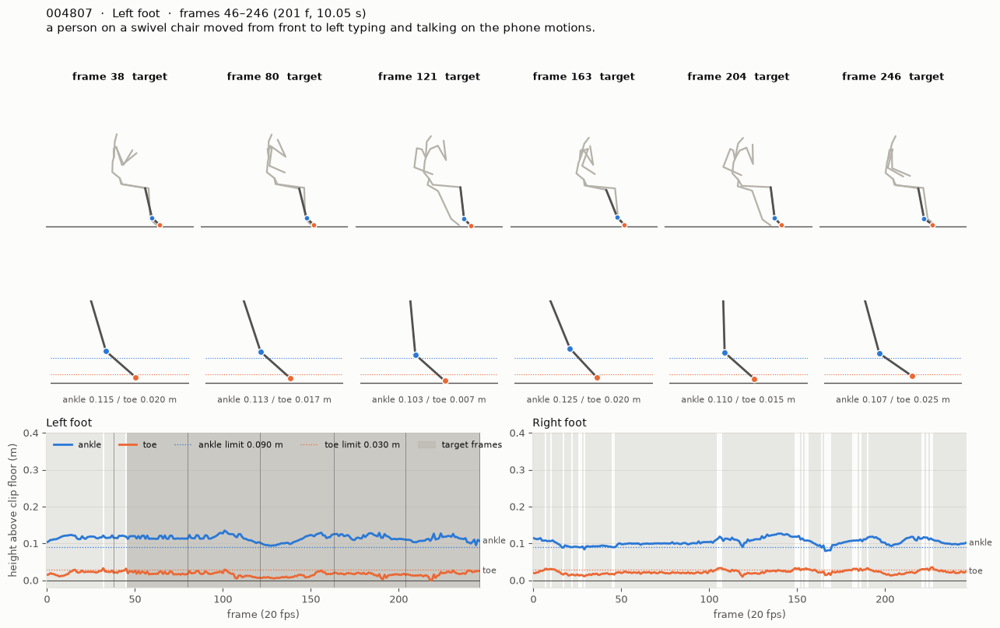

013577 | 발 L | 프레임 0–219 | 220프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
459,013577,L,0,the person is turning their steering wheel.,0.1054,0.0062,0.0032,height,True,2
460,013577,L,1,the person is turning their steering wheel.,0.1052,0.0059,0.0022,height,True,2
461,013577,L,2,the person is turning their steering wheel.,0.1046,0.0068,0.0019,height,True,2
462,013577,L,3,the person is turning their steering wheel.,0.1051,0.0097,0.0027,height,True,2
463,013577,L,4,the person is turning their steering wheel.,0.1035,0.0067,0.0034,height,True,2
464,013577,L,5,the person is turning their steering wheel.,0.1037,0.0085,0.0023,height,True,2
465,013577,L,6,the person is turning their steering wheel.,0.1059,0.0059,0.0022,height,True,2
466,013577,L,7,the person is turning their steering wheel.,0.1049,0.0087,0.0026,height,True,2
467,013577,L,8,the person is turning their steering wheel.,0.1061,0.0063,0.0006,height,True,2
468,013577,L,9,the person is turning their steering wheel.,0.1066,0.0091,0.0008,height,True,2


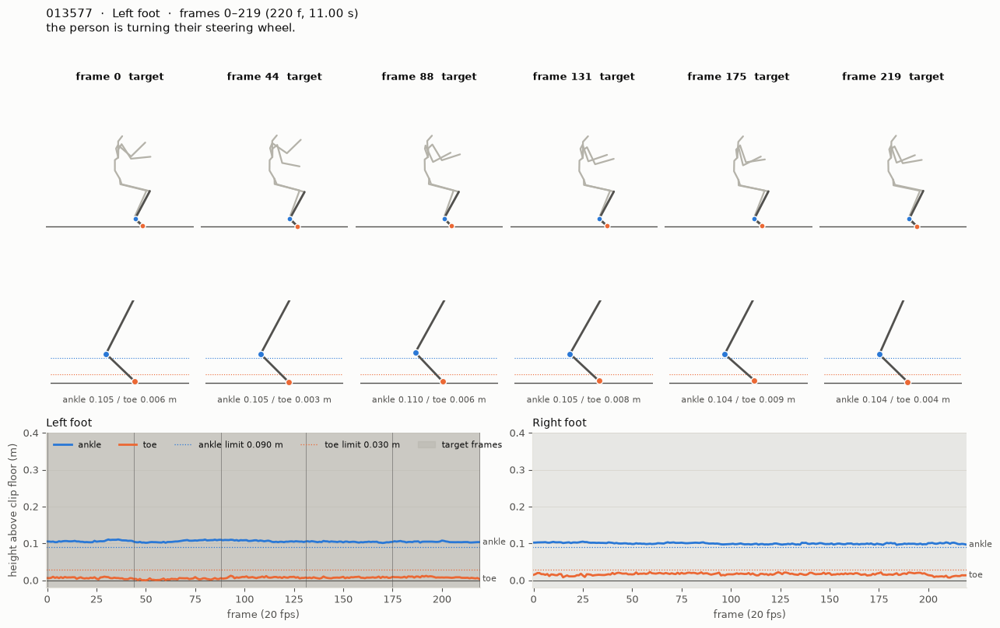

M010541 | 발 L | 프레임 0–210 | 211프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
1339,M010541,L,0,a man is crouching then raises his right hand to his head the lowers it back down.,0.0948,0.0029,0.0036,height,True,4
1340,M010541,L,1,a man is crouching then raises his right hand to his head the lowers it back down.,0.0978,0.0119,0.0031,height,True,4
1341,M010541,L,2,a man is crouching then raises his right hand to his head the lowers it back down.,0.0948,0.0042,0.0024,height,True,4
1342,M010541,L,3,a man is crouching then raises his right hand to his head the lowers it back down.,0.0966,0.0114,0.0016,height,True,4
1343,M010541,L,4,a man is crouching then raises his right hand to his head the lowers it back down.,0.0975,0.0090,0.0031,height,True,4
1344,M010541,L,5,a man is crouching then raises his right hand to his head the lowers it back down.,0.0955,0.0055,0.0013,height,True,4
1345,M010541,L,6,a man is crouching then raises his right hand to his head the lowers it back down.,0.0944,0.0043,0.0026,height,True,4
1346,M010541,L,7,a man is crouching then raises his right hand to his head the lowers it back down.,0.0956,0.0088,0.0013,height,True,4
1347,M010541,L,8,a man is crouching then raises his right hand to his head the lowers it back down.,0.0954,0.0081,0.0037,height,True,4
1348,M010541,L,9,a man is crouching then raises his right hand to his head the lowers it back down.,0.0961,0.0062,0.0027,height,True,4


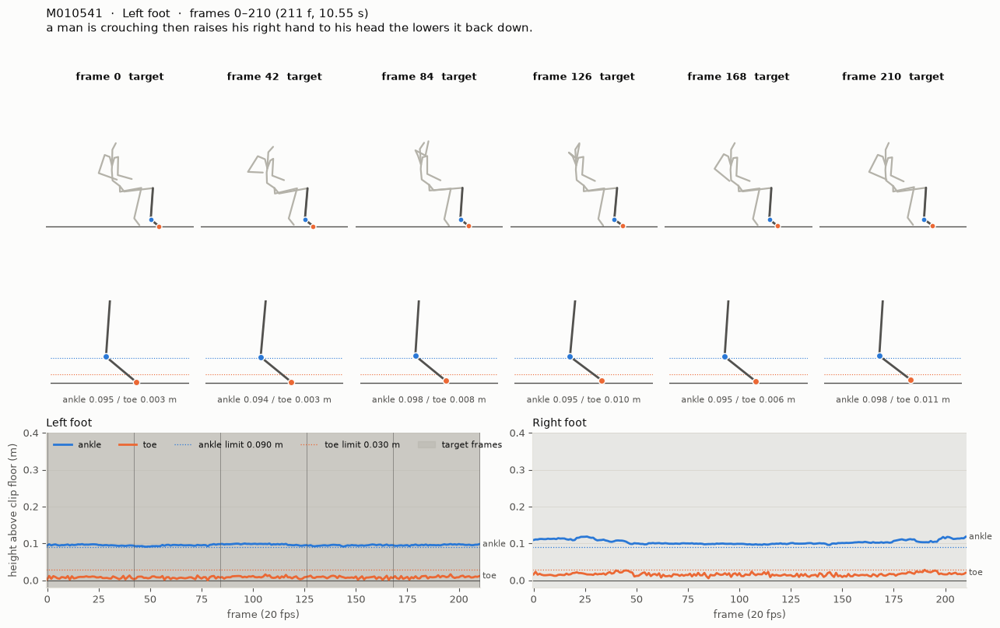

005046 | 발 R | 프레임 0–207 | 208프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
2382,005046,R,0,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1146,0.0071,0.0017,height,True,6
2383,005046,R,1,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1147,0.0062,0.0060,height,True,6
2384,005046,R,2,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1156,0.0105,0.0065,height,True,6
2385,005046,R,3,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1192,0.0130,0.0051,height,True,6
2386,005046,R,4,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1209,0.0142,0.0069,height,True,6
2387,005046,R,5,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1220,0.0133,0.0090,height,True,6
2388,005046,R,6,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1262,0.0150,0.0063,height,True,6
2389,005046,R,7,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1262,0.0173,0.0056,height,True,6
2390,005046,R,8,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1264,0.0143,0.0036,height,True,6
2391,005046,R,9,"person bends elbows so the hands are in front of the face, then drops the right arm an...",0.1265,0.0128,0.0056,height,True,6


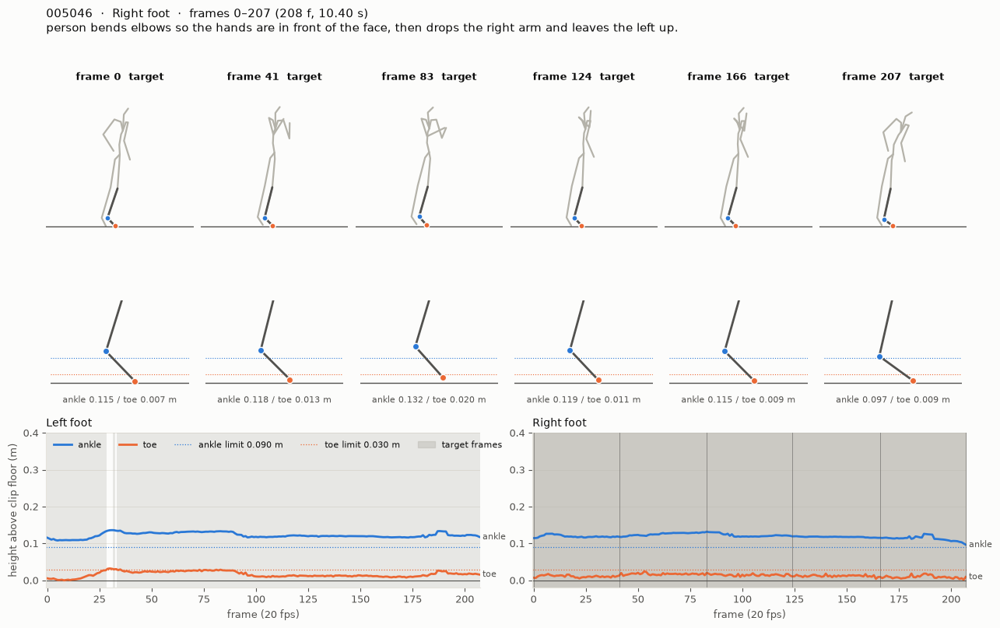

012459 | 발 L | 프레임 0–198 | 199프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
3412,012459,L,0,a person turns steering wheel with both hands.,0.1025,0.0113,0.0023,height,True,9
3413,012459,L,1,a person turns steering wheel with both hands.,0.1015,0.0086,0.0028,height,True,9
3414,012459,L,2,a person turns steering wheel with both hands.,0.1007,0.0125,0.0012,height,True,9
3415,012459,L,3,a person turns steering wheel with both hands.,0.1005,0.0097,0.0017,height,True,9
3416,012459,L,4,a person turns steering wheel with both hands.,0.0994,0.0083,0.0007,height,True,9
3417,012459,L,5,a person turns steering wheel with both hands.,0.0997,0.0115,0.0014,height,True,9
3418,012459,L,6,a person turns steering wheel with both hands.,0.0997,0.0101,0.0063,height,True,9
3419,012459,L,7,a person turns steering wheel with both hands.,0.1043,0.0082,0.0033,height,True,9
3420,012459,L,8,a person turns steering wheel with both hands.,0.1024,0.0092,0.0039,height,True,9
3421,012459,L,9,a person turns steering wheel with both hands.,0.1035,0.0058,0.0023,height,True,9


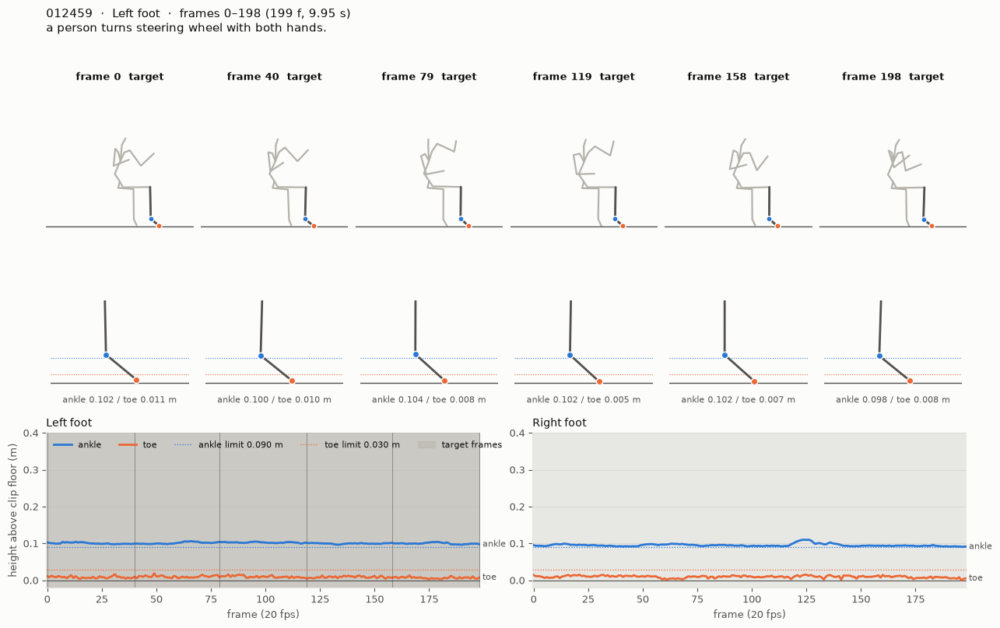

M010067 | 발 L | 프레임 0–181 | 182프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
4206,M010067,L,0,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1269,0.0160,0.0013,height,True,11
4207,M010067,L,1,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1262,0.0154,0.0012,height,True,11
4208,M010067,L,2,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1270,0.0151,0.0016,height,True,11
4209,M010067,L,3,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1280,0.0153,0.0016,height,True,11
4210,M010067,L,4,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1279,0.0144,0.0008,height,True,11
4211,M010067,L,5,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1280,0.0139,0.0027,height,True,11
4212,M010067,L,6,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1276,0.0151,0.0020,height,True,11
4213,M010067,L,7,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1267,0.0157,0.0015,height,True,11
4214,M010067,L,8,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1274,0.0172,0.0020,height,True,11
4215,M010067,L,9,a man is bent down close to the floor and bouncing on his feet for 5 seconds then begi...,0.1271,0.0168,0.0023,height,True,11


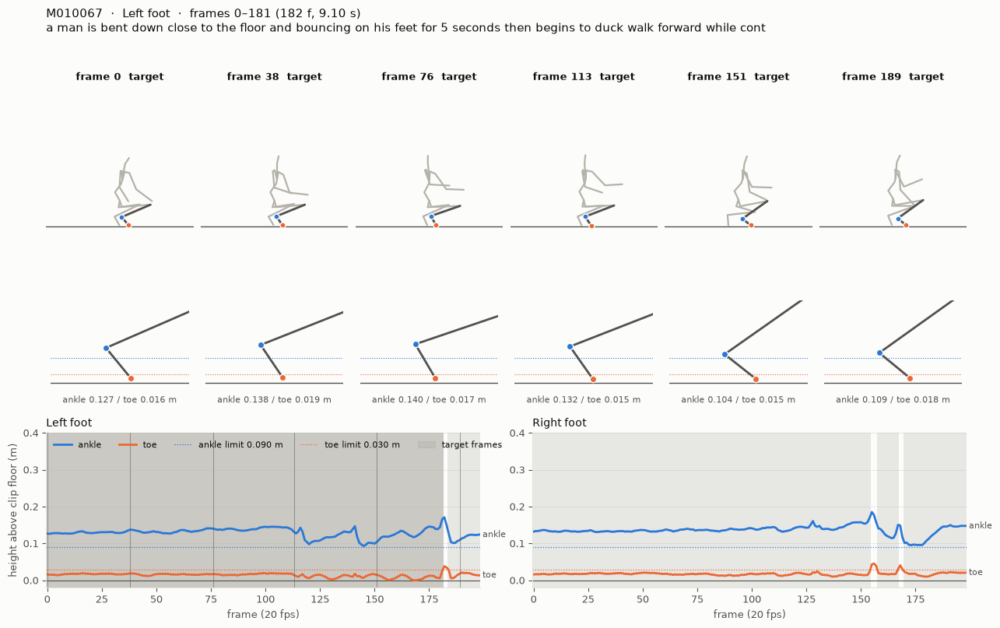

005096 | 발 L | 프레임 0–193 | 194프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
4597,005096,L,0,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1060,0.0069,0.0028,height,True,12
4598,005096,L,1,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1067,0.0091,0.0038,height,True,12
4599,005096,L,2,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1089,0.0129,0.0065,height,True,12
4600,005096,L,3,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1047,0.0102,0.0080,height,True,12
4601,005096,L,4,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1109,0.0134,0.0032,height,True,12
4602,005096,L,5,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1121,0.0106,0.0049,height,True,12
4603,005096,L,6,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1077,0.0101,0.0034,height,True,12
4604,005096,L,7,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1081,0.0104,0.0036,height,True,12
4605,005096,L,8,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1047,0.0089,0.0021,height,True,12
4606,005096,L,9,a person is sitting and picks up something with his right hand and moves it to his fac...,0.1039,0.0088,0.0024,height,True,12


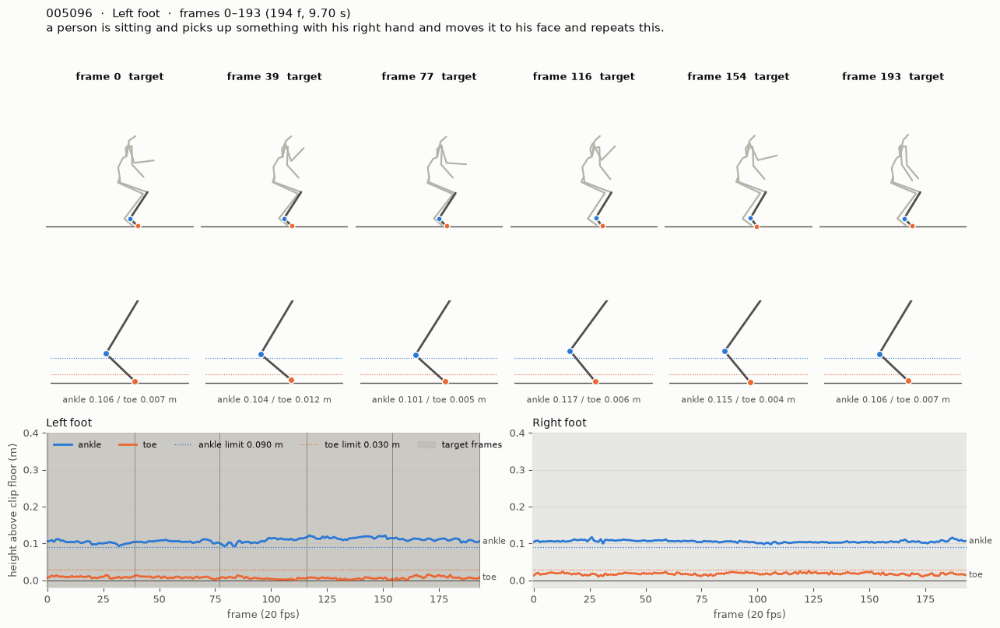

006164 | 발 R | 프레임 0–198 | 199프레임 (앞 20행만 표시)


,clip,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span,clip_rank
5561,006164,R,0,the person was doing upper body stretches.,0.1459,0.0240,0.0268,height,True,14
5562,006164,R,1,the person was doing upper body stretches.,0.1369,0.0125,0.0094,height,True,14
5563,006164,R,2,the person was doing upper body stretches.,0.1303,0.0060,0.0067,height,True,14
5564,006164,R,3,the person was doing upper body stretches.,0.1271,0.0039,0.0051,height,True,14
5565,006164,R,4,the person was doing upper body stretches.,0.1271,0.0029,0.0041,height,True,14
5566,006164,R,5,the person was doing upper body stretches.,0.1285,0.0029,0.0032,height,True,14
5567,006164,R,6,the person was doing upper body stretches.,0.1294,0.0030,0.0025,height,True,14
5568,006164,R,7,the person was doing upper body stretches.,0.1298,0.0031,0.0022,height,True,14
5569,006164,R,8,the person was doing upper body stretches.,0.1308,0.0035,0.0042,height,True,14
5570,006164,R,9,the person was doing upper body stretches.,0.1331,0.0040,0.0058,height,True,14


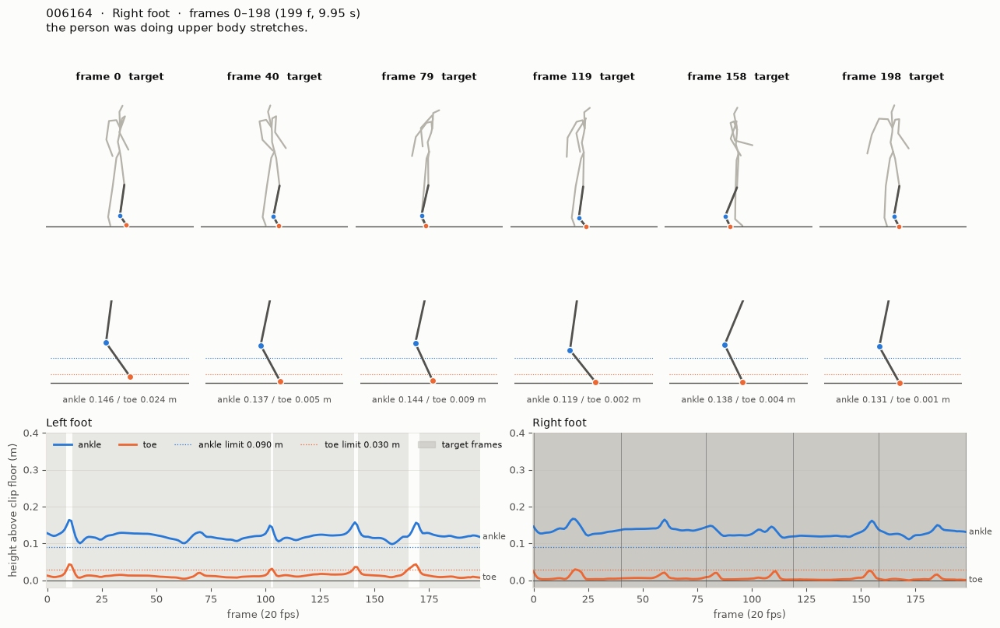

In [6]:
# 순위 상위 클립 시각화
_ = visualize_ranked(rank['clip'].tolist(), joints, captions, frame_df, VIS_TOP_N, VIS_RANK_START)

## 4. 특정 클립 보기

맨 위 셀의 `INSPECT_CLIP`에 표에서 고른 클립 이름을 넣고 실행합니다.

In [7]:
# 표에서 고른 클립 한 개를 시각화
if INSPECT_CLIP is None:
    print('INSPECT_CLIP이 None이라 건너뜀')
else:
    visualize_clip(INSPECT_CLIP, joints, captions, frame_df)

INSPECT_CLIP이 None이라 건너뜀
